In [24]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense,Input
import pandas as pd
from sklearn.model_selection import train_test_split

In [25]:
data=pd.read_csv('cifar-10.csv')
y=data['label'].values
x=data.drop('label',axis=1).values

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
x_train=x_train/255.0
x_test=x_test/255.0

In [26]:
x_train = x_train.reshape(-1, 32, 32, 3)
x_test = x_test.reshape(-1, 32, 32, 3)

In [27]:
model = Sequential([
    Input(shape=x_train.shape[1:]),
         Conv2D(32,(3,3),activation='relu'),
         MaxPooling2D((2,2)),
         Conv2D(64,(3,3),activation='relu'),
         MaxPooling2D((2,2)),
         Flatten(),
         Dense(64,activation='relu'),
         Dense(10,activation='softmax')         
])

In [28]:
print(x_train[0].shape)

(32, 32, 3)


In [29]:
model.compile(optimizer='adam',
             loss='sparse_categorical_crossentropy',
             metrics=['accuracy'])

In [30]:
history = model.fit(
    x_train, y_train, 
    epochs=10, 
    batch_size=64, 
    validation_data=(x_test, y_test)
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 24s 32ms/step - accuracy: 0.3699 - loss: 1.7387 - val_accuracy: 0.4396 - val_loss: 1.5403
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.4971 - loss: 1.4217 - val_accuracy: 0.5265 - val_loss: 1.3525
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.5418 - loss: 1.2989 - val_accuracy: 0.5551 - val_loss: 1.2838
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.5750 - loss: 1.2176 - val_accuracy: 0.5657 - val_loss: 1.2418
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.5964 - loss: 1.1554 - val_accuracy: 0.5913 - val_loss: 1.1689
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.6141 - loss: 1.0968 - val_accuracy: 0.5840 - val_loss: 1.1821
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.6338 - loss: 1.0491 - val_accuracy: 0.6070 - val_loss: 1.1373
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6498 - loss: 1.0045 - 

In [31]:
print("\n--- Stage D: Estimating performance ---")
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Final Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")


--- Stage D: Estimating performance ---
Final Test Loss: 1.1579
Final Test Accuracy: 60.67%


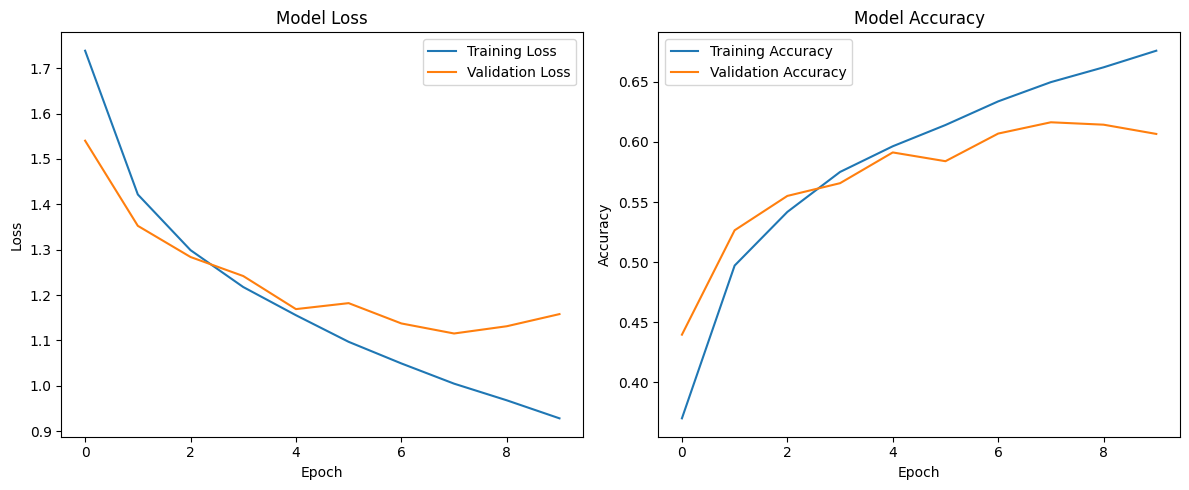

In [32]:
plt.figure(figsize=(12, 5))

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()